<a href="https://colab.research.google.com/github/ashwiniv07/A-Synergistic-Deep-Fusion-and-Adversarial-Defense-Framework-/blob/main/InsiderThreat_NB1_Data_and_Features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ===== 1. Setup =====
import os, glob, tarfile, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE    = '/content/drive/MyDrive/paper 5' if IN_COLAB else os.environ.get('CERT_BASE', './CERT_r42')   # Drive folder with both archives
WORK    = '/content/cert' if IN_COLAB else os.path.join(BASE, 'unpacked')   # Colab local disk is faster than Drive
OUT_DIR = os.path.join(BASE, 'outputs')
FIG_DIR = os.path.join(BASE, 'figures')
for d in (WORK, OUT_DIR, FIG_DIR): os.makedirs(d, exist_ok=True)

DATE_FMT   = '%m/%d/%Y %H:%M:%S'   # CERT format, e.g. 01/02/2010 06:49:00
WORK_START, WORK_END = 8, 18       # working hours [08:00, 18:00)
CHUNK      = 2_000_000             # rows per chunk; use 1_000_000 if Colab RAM runs short
SEED       = 42
SPLIT_MODE = 'auto'                # 'auto' | 'time' | 'user'
USE_PSYCHOMETRIC = False             # OCEAN scores are latent (not observable in a real deployment); keep off for the main run
MIN_TEST_INSIDERS = 10             # answer-key check: chronological test period holds 14 insiders (4/8/1 per scenario)

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight'); plt.show()
def show(df):
    display(df) if IN_COLAB else print(df)
print('BASE:', BASE)

Mounted at /content/drive
BASE: /content/drive/MyDrive/paper 5


In [ ]:
# ===== 2. Unpack archives and inventory the log files =====
def unpack(archive, dest):
    if not os.path.exists(archive):
        print('Not found (skipping):', archive); return
    marker = os.path.join(dest, '.unpacked_' + os.path.basename(archive))
    if os.path.exists(marker):
        print('Already unpacked:', os.path.basename(archive)); return
    t = time.time(); print('Unpacking', os.path.basename(archive), '... (r4.2 takes several minutes)')
    with tarfile.open(archive, 'r:bz2') as tf:
        tf.extractall(dest)
    open(marker, 'w').close(); print(f'  done in {time.time()-t:.0f}s')

unpack(os.path.join(BASE, 'r4.2.tar.bz2'), WORK)
unpack(os.path.join(BASE, 'answers.tar.bz2'), WORK)

def find_one(pattern):
    hits = sorted(glob.glob(os.path.join(WORK, '**', pattern), recursive=True)) or \
           sorted(glob.glob(os.path.join(BASE, '**', pattern), recursive=True))
    return hits[0] if hits else None

COLS = {
    'logon':  ['id', 'date', 'user', 'pc', 'activity'],
    'device': ['id', 'date', 'user', 'pc', 'activity'],
    'file':   ['id', 'date', 'user', 'pc', 'filename', 'content'],
    'email':  ['id', 'date', 'user', 'pc', 'to', 'cc', 'bcc', 'from', 'size', 'attachments', 'content'],
    'http':   ['id', 'date', 'user', 'pc', 'url', 'content'],
}
LOG = {k: find_one(f'{k}.csv') for k in COLS}
INSIDERS_CSV = find_one('insiders.csv')
PSYCHO_CSV   = find_one('psychometric.csv')
assert all(LOG.values()), f'Missing log files: {[k for k, v in LOG.items() if not v]}'
assert INSIDERS_CSV, 'answers/insiders.csv not found — unpack answers.tar.bz2'

def has_header(path):
    with open(path, 'r', errors='ignore') as f:
        return f.readline().lower().startswith('id,')

def read_log(name, usecols, chunksize=CHUNK):
    names = COLS[name]
    return pd.read_csv(LOG[name], header=0 if has_header(LOG[name]) else None, names=names,
                       usecols=[names.index(c) for c in usecols], chunksize=chunksize,
                       on_bad_lines='skip', low_memory=False)

inv = pd.DataFrame([{'source': k, 'size_GB': round(os.path.getsize(v) / 1e9, 3), 'has_header': has_header(v)}
                    for k, v in LOG.items()])
show(inv)

Unpacking r4.2.tar.bz2 ... (r4.2 takes several minutes)


/tmp/ipykernel_497/1296372927.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(dest)


  done in 1233s
Unpacking answers.tar.bz2 ... (r4.2 takes several minutes)
  done in 1s


,source,size_GB,has_header
0,logon,0.059,True
1,device,0.029,True
2,file,0.193,True
3,email,1.362,True
4,http,14.536,True


In [ ]:
# ===== 3. Answer key: insiders, malicious events and their channels =====
import csv

ins = pd.read_csv(INSIDERS_CSV, dtype={'user': 'string', 'details': 'string'})
ins['user'] = ins['user'].astype('string').str.strip()
ins['scenario'] = ins['scenario'].astype('string').str.strip()
ins['dataset_num'] = pd.to_numeric(ins['dataset'], errors='coerce')
ins = ins[ins['dataset_num'].eq(4.2)].copy()
assert not ins.empty, 'No dataset=4.2 rows found in answers/insiders.csv'
assert {'user', 'scenario', 'details'}.issubset(ins.columns), \
       f'Unexpected insiders.csv columns: {list(ins.columns)}'
INSIDERS = set(ins['user'].dropna().astype(str))
print(f'Insiders in r4.2 answer key: {len(INSIDERS)}')
show(ins.groupby('scenario')['user'].nunique().rename('insiders'))

# The `details` column names the per-insider answer files (for example,
# r4.2-1-AAM0658.csv). Search recursively under the extracted answers folder
# so this works whether KiltHub places those files directly under answers/ or
# in a nested directory.
answer_root = os.path.dirname(INSIDERS_CSV)
answer_file_index = {}
for root, _, files in os.walk(answer_root):
    for name in files:
        if name.lower().endswith('.csv') and name.lower() != 'insiders.csv':
            answer_file_index.setdefault(name.lower(), os.path.join(root, name))

missing_answer_files = []
answer_jobs = []
for r in ins.itertuples(index=False):
    detail = str(r.details).strip()
    detail_name = os.path.basename(detail)
    fp = answer_file_index.get(detail_name.lower())
    if fp is None:
        missing_answer_files.append(detail_name)
    else:
        answer_jobs.append((str(r.scenario), str(r.user).strip(), fp))

if missing_answer_files:
    raise FileNotFoundError(
        f'{len(missing_answer_files)} per-insider answer files listed in insiders.csv '
        f'were not found under {answer_root}. Examples: {missing_answer_files[:8]}. '
        'Check that answers.tar.bz2 was fully extracted.'
    )
assert answer_jobs, 'No per-insider answer files were resolved from the answer key.'
print(f'Per-insider answer files found: {len(answer_jobs)} / {len(ins)}')

SOURCE_TO_CHANNEL = {'device': 'usb', 'file': 'usb', 'http': 'web',
                     'email': 'email', 'logon': 'access'}
rows = []
malformed_answer_rows = 0
for scen, expected_user, fp in answer_jobs:
    with open(fp, 'r', errors='replace', newline='') as f:
        for rec in csv.reader(f):
            if not rec or len(rec) < 4:
                malformed_answer_rows += 1
                continue
            src = str(rec[0]).strip().lower()
            # Ignore a possible header row; answer-event files are usually headerless.
            if src in {'source', 'log'}:
                continue
            event_date = str(rec[2]).strip()
            event_user = str(rec[3]).strip()
            if not event_user:
                malformed_answer_rows += 1
                continue
            rows.append((scen, src, event_date, event_user,
                         SOURCE_TO_CHANNEL.get(src, 'unknown'), expected_user))

mal = pd.DataFrame(rows, columns=['scenario', 'source', 'date', 'user', 'channel', 'answer_file_user'])
assert not mal.empty, 'No event rows were read from the per-insider answer files.'
mal['date'] = pd.to_datetime(mal['date'], format=DATE_FMT, errors='coerce')
mal['day'] = mal['date'].dt.normalize()
bad_dates = int(mal['date'].isna().sum())
mal = mal.dropna(subset=['date']).copy()

chan_tab = pd.crosstab(mal['scenario'], mal['source'], margins=True)
chan_tab.to_csv(os.path.join(OUT_DIR, 'channel_mapping_by_scenario.csv'))
n_unknown = int((mal['channel'] == 'unknown').sum())
print(f'Malicious answer-key events: {len(mal):,} | unknown source: {n_unknown} | '
      f'unparseable dates: {bad_dates} | malformed rows skipped: {malformed_answer_rows}')
show(chan_tab)
if bad_dates:
    print('WARNING: Some answer-key event timestamps did not match DATE_FMT; inspect these before modelling.')
if n_unknown:
    print('WARNING: Unrecognised source tags remain labelled unknown; do not silently assign a channel.')

# One row per malicious user-day, with one indicator per observed channel.
mal_ud = (mal.assign(v=1).pivot_table(index=['user', 'day'], columns='channel', values='v',
                                      aggfunc='max', fill_value=0).reset_index())
for c in ['usb', 'web', 'email', 'access']:
    if c not in mal_ud.columns:
        mal_ud[c] = 0
mal_ud = mal_ud.rename(columns={c: f'ch_{c}' for c in ['usb', 'web', 'email', 'access']})
scenario_by_day = (mal.groupby(['user', 'day'])['scenario']
                     .agg(lambda s: '|'.join(sorted(set(s.astype(str))))).reset_index())
mal_ud = mal_ud.merge(scenario_by_day, on=['user', 'day'], how='left')
mal_ud['y'] = 1
assert not mal_ud.duplicated(['user', 'day']).any(), 'Duplicate malicious user-day labels detected.'
print(f'Malicious user-days: {len(mal_ud):,} from {mal_ud["user"].nunique()} accounts '
      f'({len(INSIDERS)} insiders; scenario 3 also marks supervisor accounts the insider misused)')
print('CHECK 1 (answer key): per-insider files resolved from insiders.csv details; '
      'channels assigned from event source tags.')


Insiders in r4.2 answer key: 70


,insiders
scenario,
1,30
2,30
3,10


Per-insider answer files found: 70 / 70
Malicious answer-key events: 7,323 | unknown source: 0 | unparseable dates: 0 | malformed rows skipped: 0


source,device,email,file,http,logon,All
scenario,,,,,,
1,138,0,0,69,138,345
2,2607,420,0,3738,0,6765
3,40,50,10,53,60,213
All,2785,470,10,3860,198,7323


Malicious user-days: 986 from 72 accounts (70 insiders; scenario 3 also marks supervisor accounts the insider misused)
CHECK 1 (answer key): per-insider files resolved from insiders.csv details; channels assigned from event source tags.


In [ ]:
# ===== 4. Per-source user-day features (chunked; safe for Colab RAM) =====
def to_time(s):
    d = pd.to_datetime(s, format=DATE_FMT, errors='coerce')
    return d.dt.normalize(), d.dt.hour, ((d.dt.hour < WORK_START) | (d.dt.hour >= WORK_END)).astype(int)

def chunked_userday(name, usecols, build):
    """Read a log in chunks, build per-row feature columns, sum them per user-day."""
    t, parts, n = time.time(), [], 0
    for ch in read_log(name, usecols):
        day, hour, ah = to_time(ch['date'])
        g = build(ch, hour, ah); g['user'] = ch['user'].values; g['day'] = day.values
        parts.append(g.groupby(['user', 'day']).sum()); n += len(ch)
        print(f'  {name}: {n:,} rows | {time.time()-t:.0f}s', end='\r')
    out = pd.concat(parts).groupby(level=[0, 1]).sum()
    print(f'  {name}: {n:,} rows -> {len(out):,} user-days in {time.time()-t:.0f}s')
    return out

# 4a Logon
def b_logon(ch, hour, ah):
    on = (ch['activity'].astype(str).str.lower() == 'logon').astype(int)
    return pd.DataFrame({'logon_n': on, 'logoff_n': 1 - on, 'logon_afterhours': on * ah,
                         'logon_early': on * (hour < 6).astype(int), 'logon_late': on * (hour >= 21).astype(int)})
F_logon = chunked_userday('logon', ['date', 'user', 'pc', 'activity'], b_logon)
# Distinct PCs used per user-day. We deliberately do NOT infer each user's
# 'usual PC' from the complete dataset: that would use future test-period data.
# Keep only unique user-day-PC tuples while streaming the second logon pass.
pc_parts = []
for ch in read_log('logon', ['date', 'user', 'pc']):
    pc_day = pd.DataFrame({
        'user': ch['user'].astype(str).values,
        'day': pd.to_datetime(ch['date'], format=DATE_FMT, errors='coerce').dt.normalize().values,
        'pc': ch['pc'].astype(str).values,
    }).dropna(subset=['day']).drop_duplicates()
    pc_parts.append(pc_day)
pc_unique = pd.concat(pc_parts, ignore_index=True).drop_duplicates()
logon_pc_daily = pc_unique.groupby(['user', 'day'])['pc'].nunique().rename('logon_n_pc')
# Leakage-free 'new PC' signal: PCs this user had never logged into on any EARLIER day.
# Uses only data up to day t (first-seen date), unlike a full-period 'usual PC'.
first_seen = pc_unique.groupby(['user', 'pc'])['day'].transform('min')
user_start = pc_unique.groupby('user')['day'].transform('min')
pc_unique['new_pc'] = ((pc_unique['day'] == first_seen) & (pc_unique['day'] > user_start)).astype(int)
logon_new_pc = pc_unique.groupby(['user', 'day'])['new_pc'].sum().rename('logon_new_pc')
F_logon = F_logon.join(logon_pc_daily).join(logon_new_pc)
del pc_parts, pc_unique, logon_pc_daily, logon_new_pc, first_seen, user_start

# 4b Device (USB)
def b_device(ch, hour, ah):
    con = (ch['activity'].astype(str).str.lower() == 'connect').astype(int)
    return pd.DataFrame({'usb_connect': con, 'usb_afterhours': con * ah})
F_device = chunked_userday('device', ['date', 'user', 'activity'], b_device)

# 4c File (in r4.2: copies to removable media)
def b_file(ch, hour, ah):
    ext = ch['filename'].astype(str).str.lower().str.extract(r'\.(\w+)$')[0]
    return pd.DataFrame({'file_n': 1, 'file_afterhours': ah,
                         'file_doc': ext.isin(['doc', 'docx', 'pdf', 'txt']).astype(int),
                         'file_exe': ext.isin(['exe']).astype(int),
                         'file_zip': ext.isin(['zip', 'rar', '7z']).astype(int),
                         'file_img': ext.isin(['jpg', 'jpeg', 'png', 'gif']).astype(int)})
F_file = chunked_userday('file', ['date', 'user', 'filename'], b_file)

# 4d Email (content column skipped)
INTERNAL_DOMAIN = '@dtaa.com'
def b_email(ch, hour, ah):
    rcpt = (ch['to'].fillna('') + ';' + ch['cc'].fillna('') + ';' + ch['bcc'].fillna('')).str.lower()
    n_rcpt = rcpt.str.count('@'); n_ext = n_rcpt - rcpt.str.count(INTERNAL_DOMAIN)
    att = pd.to_numeric(ch['attachments'], errors='coerce').fillna(0)
    ext_flag = (n_ext > 0).astype(int)
    return pd.DataFrame({'email_n': 1, 'email_afterhours': ah, 'email_rcpt': n_rcpt, 'email_ext_rcpt': n_ext,
                         'email_ext': ext_flag, 'email_attach': (att > 0).astype(int),
                         'email_ext_attach': ext_flag * (att > 0).astype(int),
                         'email_bcc': ch['bcc'].notna().astype(int),
                         'email_size': pd.to_numeric(ch['size'], errors='coerce').fillna(0)})
F_email = chunked_userday('email', ['date', 'user', 'to', 'cc', 'bcc', 'size', 'attachments'], b_email)
F_email['email_size'] = F_email['email_size'] / F_email['email_n'].clip(lower=1)   # mean size per email

# 4e HTTP (url only; the content column is skipped to save RAM)
KEYWORDS = {
    'job':     ['monster', 'careerbuilder', 'indeed', 'simplyhired', 'jobhunt', 'job', 'career',
                'hiring', 'linkedin', 'glassdoor', 'craigslist'],
    'leak':    ['wikileaks', 'leak'],
    'hacking': ['keylog', 'spy', 'hack', 'crack', 'exploit'],
    'cloud':   ['dropbox', 'upload', 'box.com', 'mediafire', 'rapidshare', 'megaupload'],
}
def b_http(ch, hour, ah):
    url = ch['url'].astype(str).str.lower()
    g = pd.DataFrame({'http_n': 1, 'http_afterhours': ah})
    for cat, words in KEYWORDS.items():
        g[f'http_{cat}'] = url.str.contains('|'.join(words), regex=True).astype(int)
    return g
HTTP_CACHE = os.path.join(OUT_DIR, 'http_userday.csv.gz')
if os.path.exists(HTTP_CACHE):                                  # re-runs skip the long pass
    F_http = pd.read_csv(HTTP_CACHE, parse_dates=['day']).set_index(['user', 'day'])
else:
    F_http = chunked_userday('http', ['date', 'user', 'url'], b_http)
    F_http.reset_index().to_csv(HTTP_CACHE, index=False, compression='gzip')

  logon: 854,859 rows -> 330,452 user-days in 5s
  device: 405,380 rows -> 55,717 user-days in 3s
  file: 445,581 rows -> 45,907 user-days in 6s
  email: 2,629,979 rows -> 326,985 user-days in 43s
  http: 28,434,423 rows -> 329,845 user-days in 554s


In [ ]:
# ===== 5. Merge sources, calendar features and per-user behavioural baselines =====
df = F_logon.join([F_device, F_file, F_email, F_http], how='outer').fillna(0).reset_index()
df = df.sort_values(['user', 'day']).reset_index(drop=True)
df['weekday'] = df['day'].dt.weekday
df['weekend'] = (df['weekday'] >= 5).astype(int)

# Deviation from each user's own history. shift(1) => only days BEFORE day t are used (no leakage).
BASE_FEATS = ['logon_n', 'logon_afterhours', 'logon_n_pc', 'logon_new_pc', 'usb_connect', 'usb_afterhours', 'file_n',
              'email_n', 'email_ext', 'email_ext_attach', 'http_n', 'http_afterhours',
              'http_job', 'http_leak', 'http_hacking', 'http_cloud']
WIN, EPS = 30, 1.0     # 30 previous active days; EPS keeps z finite for users with constant behaviour
g = df.groupby('user', sort=False)
for f in BASE_FEATS:
    prev = g[f].shift(1)
    mu = prev.groupby(df['user']).transform(lambda s: s.rolling(WIN, min_periods=5).mean())
    sd = prev.groupby(df['user']).transform(lambda s: s.rolling(WIN, min_periods=5).std())
    df[f'z_{f}'] = ((df[f] - mu) / (sd.fillna(0) + EPS)).fillna(0)
# first-time behaviour flags: e.g. first ever USB use or first job-site visit.
# Note: URL keyword indicators are scenario-specific cues in this synthetic benchmark;
# NB2 should include a sensitivity/ablation run without these HTTP keyword features.
for f in ['usb_connect', 'http_job', 'http_leak', 'http_hacking', 'logon_afterhours']:
    seen_before = g[f].transform(lambda s: s.shift(1).fillna(0).cumsum()) > 0
    df[f'first_{f}'] = ((df[f] > 0) & ~seen_before).astype(int)

if USE_PSYCHOMETRIC and PSYCHO_CSV:   # optional: static OCEAN scores shipped with r4.2 (latent in practice)
    psy = pd.read_csv(PSYCHO_CSV).rename(columns={'user_id': 'user'})[['user', 'O', 'C', 'E', 'A', 'N']]
    df = df.merge(psy.add_prefix('psy_').rename(columns={'psy_user': 'user'}), on='user', how='left')
print('Feature table:', df.shape)

Feature table: (330452, 55)


In [ ]:
# ===== 6. Labels and train/val/test split =====
df = df.merge(mal_ud[['user', 'day', 'y', 'scenario', 'ch_usb', 'ch_web', 'ch_email', 'ch_access']],
              on=['user', 'day'], how='left')
df['y'] = df['y'].fillna(0).astype(int)
df[['ch_usb', 'ch_web', 'ch_email', 'ch_access']] = df[['ch_usb', 'ch_web', 'ch_email', 'ch_access']].fillna(0).astype(int)
df['scenario'] = df['scenario'].fillna('0')
assert int(df['y'].sum()) > 0, 'No positive user-days were labelled. Check answer-key parsing and event dates.'
assert df[['ch_usb', 'ch_web', 'ch_email', 'ch_access']].to_numpy().sum() > 0, 'No malicious channel indicators found.'
df['is_insider'] = df['user'].isin(INSIDERS).astype(int)
lost = len(mal_ud) - df['y'].sum()
print(f'Positive user-days: {df["y"].sum()} of {len(df):,} ({100*df["y"].mean():.3f}%) | '
      f'answer-key days with no log activity row: {lost}')

# (a) chronological 60/20/20
days = np.sort(df['day'].unique())
cut1, cut2 = days[int(len(days) * .6)], days[int(len(days) * .8)]
df['split_time'] = np.where(df['day'] < cut1, 'train', np.where(df['day'] < cut2, 'val', 'test'))

# (b) insider-disjoint 60/20/20: every user is in exactly one partition, stratified by scenario
rng = np.random.default_rng(SEED)
user_scen = df.groupby('user')['scenario'].agg(lambda s: s[s != '0'].iloc[0] if (s != '0').any() else '0')
assign = {}
for scen, users in user_scen.groupby(user_scen):
    u = rng.permutation(users.index.values); n = len(u)
    a, b = int(round(n * .6)), int(round(n * .8))
    assign.update({x: 'train' for x in u[:a]}); assign.update({x: 'val' for x in u[a:b]})
    assign.update({x: 'test' for x in u[b:]})
df['split_user'] = df['user'].map(assign)

chk = pd.DataFrame({m: df[df.y == 1].groupby(f'split_{m}')['user'].nunique() for m in ['time', 'user']}
                   ).reindex(['train', 'val', 'test']).fillna(0).astype(int)
chk.columns = ['insiders_time_split', 'insiders_user_split']
show(chk)
test_ins_time = chk.loc['test', 'insiders_time_split']
if SPLIT_MODE == 'auto':
    SPLIT_MODE = 'time' if test_ins_time >= MIN_TEST_INSIDERS else 'user'
df['split'] = df[f'split_{SPLIT_MODE}']
print(f'CHECK 2 (split): {test_ins_time} insiders in the chronological test period -> using SPLIT_MODE = "{SPLIT_MODE}"')
show(df.groupby('split')['y'].agg(['size', 'sum']).rename(columns={'size': 'user_days', 'sum': 'malicious'}))

Positive user-days: 986 of 330,452 (0.298%) | answer-key days with no log activity row: 0


,insiders_time_split,insiders_user_split
train,48,43
val,24,15
test,14,14


CHECK 2 (split): 14 insiders in the chronological test period -> using SPLIT_MODE = "time"


,user_days,malicious
split,,
test,61473,156
train,208167,571
val,60812,259


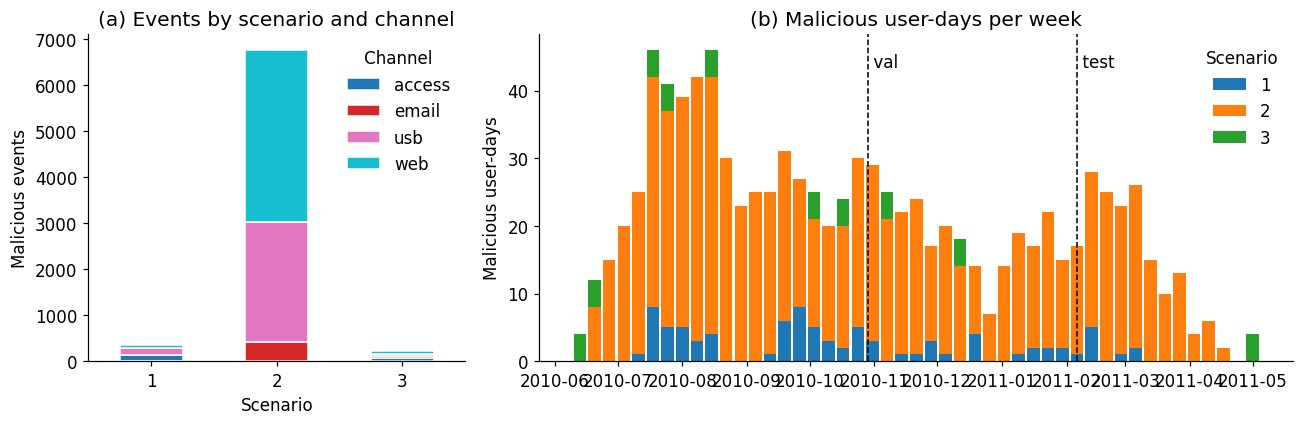

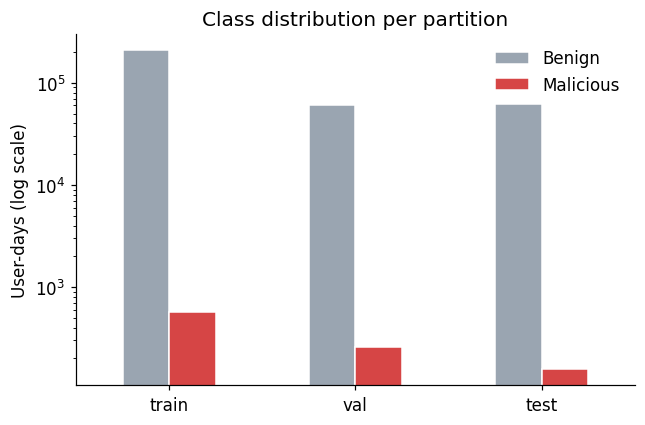

,source,size_GB,user_days_with_activity,malicious_events
0,logon,0.059,330268,198
1,device,0.029,55717,2785
2,file,0.193,45907,10
3,email,1.362,326985,470
4,http,14.536,329845,3860


In [ ]:
# ===== 7. Dataset figures for the paper =====
# Fig. 2: (a) malicious events by scenario and channel, (b) malicious user-days per week
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 2]})
ct = pd.crosstab(mal['scenario'], mal['channel'])
ct.plot(kind='bar', stacked=True, ax=ax[0], colormap='tab10', edgecolor='white')
ax[0].set_xlabel('Scenario'); ax[0].set_ylabel('Malicious events'); ax[0].set_title('(a) Events by scenario and channel')
ax[0].tick_params(axis='x', rotation=0); ax[0].legend(title='Channel', frameon=False)
tl = df[df.y == 1].groupby([pd.Grouper(key='day', freq='W'), 'scenario']).size().unstack(fill_value=0)
bottom = np.zeros(len(tl))
for k, sc in enumerate(tl.columns):
    ax[1].bar(tl.index, tl[sc].values, width=6, bottom=bottom, label=sc, color=plt.cm.tab10(k)); bottom += tl[sc].values
if SPLIT_MODE == 'time':
    for c, lab in [(cut1, 'val'), (cut2, 'test')]:
        ax[1].axvline(c, color='k', ls='--', lw=1); ax[1].text(c, ax[1].get_ylim()[1] * .9, f' {lab}')
ax[1].set_ylabel('Malicious user-days'); ax[1].set_title('(b) Malicious user-days per week')
ax[1].legend(title='Scenario', frameon=False)
savefig('Fig2_dataset_overview.png')

# Fig. 3: class imbalance per split
cnt = df.groupby(['split', 'y']).size().unstack().reindex(['train', 'val', 'test'])
cnt.columns = ['Benign', 'Malicious']
cnt.plot(kind='bar', logy=True, figsize=(6, 4), color=['#9aa5b1', '#d64545'], edgecolor='white')
plt.ylabel('User-days (log scale)'); plt.xlabel(''); plt.xticks(rotation=0)
plt.title('Class distribution per partition'); plt.legend(frameon=False)
savefig('Fig3_class_distribution.png')

# Table 1 (dataset description) as CSV
tab1 = inv[['source', 'size_GB']].copy()
tab1['user_days_with_activity'] = [int((df[c] > 0).sum()) for c in ['logon_n', 'usb_connect', 'file_n', 'email_n', 'http_n']]
tab1['malicious_events'] = [int((mal['source'] == s).sum()) for s in tab1['source']]
tab1.to_csv(os.path.join(OUT_DIR, 'Table1_dataset.csv'), index=False); show(tab1)

In [ ]:
# ===== 8. Save =====
FEATURES = [c for c in df.columns if c not in
            {'user', 'day', 'y', 'scenario', 'is_insider', 'split', 'split_time', 'split_user',
             'ch_usb', 'ch_web', 'ch_email', 'ch_access'}]
df.to_csv(os.path.join(OUT_DIR, 'features_userday.csv.gz'), index=False, compression='gzip')
json.dump({'features': FEATURES, 'split_mode': SPLIT_MODE, 'work_hours': [WORK_START, WORK_END],
           'n_rows': int(len(df)), 'n_pos': int(df.y.sum()), 'n_insiders': len(INSIDERS)},
          open(os.path.join(OUT_DIR, 'meta.json'), 'w'), indent=1)
print(f'Saved {len(df):,} rows x {len(FEATURES)} features to outputs/features_userday.csv.gz')
print('Figures saved in', FIG_DIR)

Saved 330,452 rows x 53 features to outputs/features_userday.csv.gz
Figures saved in /content/drive/MyDrive/paper 5/figures
